# Pair 4 — Z-Image-Turbo evaluation

**Organisation:** Amazon retail  
**Task:** Generate promotional product images from product descriptions  
**Model:** Z-Image-Turbo, using the locally downloaded SDNQ 4-bit checkpoint

## Objective

I evaluated whether Z-Image-Turbo can produce product images that follow the descriptions of 30 Amazon products. I used the same prompts and seed values planned for the FLUX.2 klein comparison. The notebook saves each generated image and records the time required for generation. Image quality and product accuracy will be assessed separately using a manual scoring rubric.

The model was used for inference only; I did not train or fine-tune it.

## 1. Setup


In [1]:
from pathlib import Path
import json
import time
import platform

import pandas as pd
import torch
from PIL import Image
from IPython.display import display

# Find Pair_04 from the current working directory
HERE = Path.cwd().resolve()
if (HERE / "prompts.csv").exists():
    BASE = HERE
elif (HERE / "Models" / "Pair_04" / "prompts.csv").exists():
    BASE = HERE / "Models" / "Pair_04"
else:
    raise FileNotFoundError("Open Jupyter in Pair_04 or the repository root (prompts.csv was not found).")

PROMPTS_FILE = BASE / "prompts.csv"
MODEL_DIR = BASE / "models" / "Z-Image-Turbo"
OUT_DIR = BASE / "results" / "Z_Image_Turbo"
IMAGE_DIR = OUT_DIR / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

HEIGHT = 512
WIDTH = 512
STEPS = 9
GUIDANCE = 0.0
SEED = 42

print("Pair 4:", BASE)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Model folder:", MODEL_DIR)
print("Outputs:", OUT_DIR)

Pair 4: C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_04
CUDA: True
GPU: NVIDIA GeForce RTX 3070 Ti Laptop GPU
Model folder: C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_04\models\Z-Image-Turbo
Outputs: C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_04\results\Z_Image_Turbo


## 2. Load the 30 evaluation prompts

These prompts were constructed from Amazon Berkeley Objects (ABO) product listings. I do not change the prompts when comparing the two models.

In [2]:
df = pd.read_csv(PROMPTS_FILE)
assert "prompt" in df.columns, "prompts.csv needs a 'prompt' column"
assert len(df) == 30, f"Expected 30 prompts, found {len(df)}"
assert df["prompt"].notna().all(), "Some prompts are missing"

if "prompt_id" not in df.columns:
    df["prompt_id"] = [f"P{i:03d}" for i in range(1, len(df) + 1)]

assert df["prompt_id"].is_unique, "Prompt IDs should be unique"
display(df[["prompt_id", "prompt"]].head(5))

,prompt_id,prompt
0,P001,Professional ecommerce photograph of a large n...
1,P002,Premium retail product photograph of a pair of...
2,P003,Realistic commercial product photograph of a h...
3,P004,Clean children's clothing catalogue photograph...
4,P005,Studio product photo of a flexible silicone ba...


## 3. Load the model

I use the locally downloaded **SDNQ 4-bit** version because my GPU has 8 GB VRAM. CPU offloading reduces GPU memory usage. This quantised version is an inference adaptation of the original model, so the comparison report should disclose the checkpoint used.

The model is loaded once and reused for all 30 images.

In [3]:
import diffusers
import sdnq  # registers the SDNQ quantisation format

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is required for this local evaluation.")
if not (MODEL_DIR / "model_index.json").exists():
    raise FileNotFoundError(f"No Diffusers checkpoint found at {MODEL_DIR}")

pipe = diffusers.ZImagePipeline.from_pretrained(
    str(MODEL_DIR),
    torch_dtype=torch.bfloat16,
    local_files_only=True,
)
pipe.enable_model_cpu_offload()
print("Loaded Z-Image-Turbo from local checkpoint")

c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-pair4\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
SDNQ: Torch Compile is not available. Falling back to PyTorch Eager mode.
SDNQ: OpenVINO MM kernels are not available! Falling back to PyTorch Eager kernels for CPU device. Error message: No module named 'openvino'
SDNQ: Triton MM kernels are not available! Falling back to PyTorch Eager kernels. Error message: No module named 'triton'
SDNQ: Triton Scaled MM kernels are not available! Falling back to PyTorch Eager kernels. Error message: No module named 'triton'
c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-pair4\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.

Loaded Z-Image-Turbo from local checkpoint


## 4. Generate and save the images

Each product receives one image. The seed for row `i` is `42 + i`, allowing the same list of seeds to be used in the FLUX.2 klein notebook. I record the generation time for each image, without including model loading.

Results are written to CSV after every image so that completed outputs are kept if the run stops. Re-running skips images already generated successfully.

In [4]:
RESULTS_CSV = OUT_DIR / "generation_results.csv"

if RESULTS_CSV.exists():
    records = pd.read_csv(RESULTS_CSV).to_dict("records")
else:
    records = []

completed = {
    str(r["prompt_id"])
    for r in records
    if r.get("status") == "success" and (IMAGE_DIR / f"{r['prompt_id']}.png").exists()
}

for i, row in df.reset_index(drop=True).iterrows():
    prompt_id = str(row["prompt_id"])
    if prompt_id in completed:
        print(f"Skipping {prompt_id} (already generated)")
        continue

    prompt = str(row["prompt"])
    seed = SEED + i
    image_path = IMAGE_DIR / f"{prompt_id}.png"
    print(f"Generating {prompt_id} ({i + 1}/{len(df)})")

    try:
        generator = torch.Generator(device="cpu").manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        start = time.perf_counter()
        image = pipe(
            prompt=prompt,
            height=HEIGHT,
            width=WIDTH,
            num_inference_steps=STEPS,
            guidance_scale=GUIDANCE,
            generator=generator,
        ).images[0]
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        seconds = time.perf_counter() - start
        image.save(image_path)
        status, error = "success", ""
        print(f"  saved {image_path.name} in {seconds:.2f}s")
    except Exception as exc:
        seconds = None
        status, error = "failed", str(exc)
        print(f"  ERROR: {error}")

    # Replace earlier failed attempts for this prompt
    records = [r for r in records if str(r["prompt_id"]) != prompt_id]
    record = {
        "prompt_id": prompt_id,
        "item_id": row.get("item_id", ""),
        "model": "Z-Image-Turbo-SDNQ-uint4-svd-r32",
        "prompt": prompt,
        "seed": seed,
        "height": HEIGHT,
        "width": WIDTH,
        "steps": STEPS,
        "guidance_scale": GUIDANCE,
        "generation_seconds": seconds,
        "image_path": str(image_path.relative_to(BASE)) if status == "success" else "",
        "status": status,
        "error": error,
    }
    records.append(record)
    pd.DataFrame(records).to_csv(RESULTS_CSV, index=False)

results = pd.read_csv(RESULTS_CSV)
display(results[["prompt_id", "seed", "generation_seconds", "status"]])

Generating P001 (1/30)


100%|██████████| 9/9 [00:14<00:00,  1.63s/it]


  saved P001.png in 19.76s
Generating P002 (2/30)


100%|██████████| 9/9 [00:08<00:00,  1.10it/s]


  saved P002.png in 11.05s
Generating P003 (3/30)


100%|██████████| 9/9 [00:08<00:00,  1.10it/s]


... (52 outputs left out)

  saved P029.png in 10.81s
Generating P030 (30/30)


100%|██████████| 9/9 [00:08<00:00,  1.03it/s]


  saved P030.png in 10.85s


,prompt_id,seed,generation_seconds,status
0,P001,42,19.761380,success
1,P002,43,11.049349,success
2,P003,44,10.206178,success
3,P004,45,10.065433,success
4,P005,46,10.044193,success
5,P006,47,10.060217,success
6,P007,48,10.861537,success
7,P008,49,10.687878,success
8,P009,50,10.468354,success
9,P010,51,10.377638,success


## 5. Summary and example outputs

Z-Image-Turbo successfully generated all 30 product images without any failures. The average generation time was 10.97 seconds per image, with a median of 10.68 seconds. Images were generated at 512 × 512 resolution using 9 inference steps on an NVIDIA RTX 3070 Ti Laptop GPU.

These results demonstrate that the model can reliably complete image generation on my local hardware. However, successful generation does not necessarily indicate good image quality or accurate product representation. I will assess these aspects through manual scoring and compare the results against FLUX.2 klein using the same 30 prompts.

,model,num_prompts,successful_images,failed_images,mean_generation_seconds,median_generation_seconds,height,width,steps,guidance_scale,base_seed
0,Z-Image-Turbo-SDNQ-uint4-svd-r32,30,30,0,10.966584,10.677874,512,512,9,0.0,42


P001


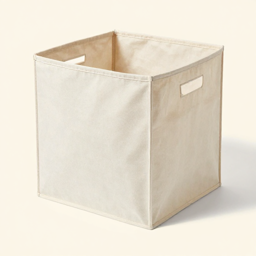

P002


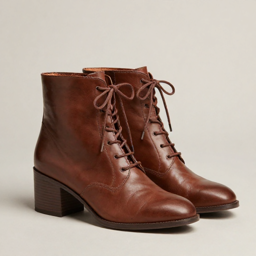

P003


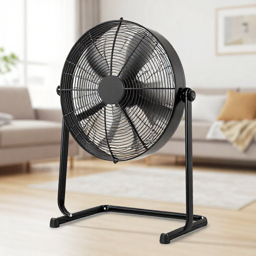

P004


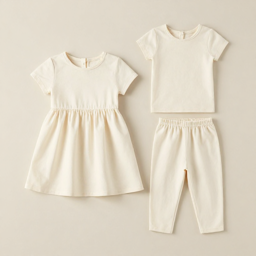

In [5]:
results = pd.read_csv(RESULTS_CSV)
success = results[results["status"] == "success"].copy()

summary = {
    "model": "Z-Image-Turbo-SDNQ-uint4-svd-r32",
    "checkpoint": str(MODEL_DIR),
    "num_prompts": len(df),
    "successful_images": len(success),
    "failed_images": len(df) - len(success),
    "mean_generation_seconds": float(success["generation_seconds"].mean()) if len(success) else None,
    "median_generation_seconds": float(success["generation_seconds"].median()) if len(success) else None,
    "height": HEIGHT,
    "width": WIDTH,
    "steps": STEPS,
    "guidance_scale": GUIDANCE,
    "base_seed": SEED,
    "pytorch_version": torch.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
}
with open(OUT_DIR / "summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

display(pd.DataFrame([summary]).drop(columns=["checkpoint", "pytorch_version", "gpu"]))

# Show a few images for visual inspection
for prompt_id in success["prompt_id"].head(4):
    print(prompt_id)
    display(Image.open(IMAGE_DIR / f"{prompt_id}.png").resize((256, 256)))

## 6. Initial reflection

This experiment generates a fixed set of 30 promotional images and records the practical inference time on my local GPU. The same prompts will be used for FLUX.2 klein to make the results comparable. Generation time does not measure visual quality, so I will assess prompt adherence, visual quality, product accuracy and suitability for retail advertising using a consistent scoring rubric in the comparison stage.

**Limitations:** The evaluation uses only 30 selected products and one seed per prompt. Generated images may not match the actual appearance of the Amazon products, because the model receives text rather than reference photos. The use of an SDNQ 4-bit checkpoint and CPU offloading may also affect results compared with other hardware or model versions.